## Daftar Isi

<div class="alert alert-block alert-info" style="margin-top: 20px">

1.  [Import Libraries](#0)<br>
2.  [Fetching Data](#1)<br>
3.  [Waffle Charts](#2) <br>
4.  [Word Clouds](#3) <br>
5.  [Plotting with Seaborn](#4) <br>
6.  [Regression Plots](#5) <br>

</div>


# Import Libraries<a id="0"></a>


In [1]:
# Import and setup matplotlib
import matplotlib as mpl
import matplotlib.patches as mpatches  # dibutuhkan untuk grafik Waffle
import matplotlib.pyplot as plt

mpl.style.use("ggplot")  # untuk gaya grafik seperti ggplot

In [2]:
# Import Primary Modules
import numpy as np  # berguna untuk banyak komputasi ilmiah di Python
import pandas as pd  # pustaka struktur data utama
from PIL import Image  # mengubah gambar menjadi array

In [3]:
# Import seaborn
import seaborn as sns

# Import worldcloud
import wordcloud

In [4]:
# periksa versi terbaru dari beberapa modul berikut
print("Matplotlib version:", mpl.__version__)
print("Seaborn version   :", sns.__version__)
print("WordClour version :", wordcloud.__version__)

Matplotlib version: 3.11.2
Seaborn version   : 0.13.2
WordClour version : 1.9.6


# Fetching Data<a id="1"></a>

Perangkat bantu: Kursus ini sangat bergantung pada [*pandas*](http://pandas.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01) dan [*Numpy*](http://www.numpy.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01) untuk data wrangling, analysis, and visualization. Pustaka plotting utama yang akan kita pelajari dalam kursus ini adalah [Matplotlib](http://matplotlib.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01).

Dataset: Immigration to Canada from 1980 to 2013 - [International migration flows to and from selected countries - The 2015 revision](https://www.un.org/development/desa/pd/data/international-migration-flows) dari website United Nation's

Dataset ini berisi data tahunan tentang arus migran internasional sebagaimana dicatat oleh negara tujuan. Data tersebut menyajikan arus masuk dan arus keluar berdasarkan tempat kelahiran, kewarganegaraan, atau tempat tinggal sebelumnya/berikutnya, baik untuk warga negara asing maupun warga negara Canada. <br><br>Dalam lab ini, kita akan fokus pada data Imigrasi Canada dan menggunakan *dataset yang sudah dibersihkan*.<br><br>
Anda dapat merujuk ke lab tentang pra-pemrosesan data di mana dataset ini dibersihkan untuk menyegarkan kembali keterampilan Pandas Anda dengan cepat. [Data pre-processing with Pandas](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/v4/DV0101EN-Exercise-Dataset-Preprocessing-Exploring-with-Pandas.ipynb)



Baca dataset yang sudah tersedia dalam folder data ke dalam dataframe *pandas*.

In [5]:
df_canada = pd.read_csv("../../data/raw/Canada.csv")

Mari kita lihat lima item pertama dalam dataset kita.

In [6]:
df_canada.head()

,Country,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
0,Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
1,Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,...,1223,856,702,560,716,561,539,620,603,15699
2,Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
3,American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
4,Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,...,0,1,1,0,0,0,0,1,1,15


Mari kita cari tahu berapa banyak entri yang ada dalam dataset kita.

In [7]:
print(df_canada.shape)

(195, 39)


In [8]:
# Gunakan column Country sebagai indeks
# untuk memudahkan dalam pencarian nama negara

df_canada.set_index("Country", inplace=True)
df_canada.head()

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Country,,,,,,,,,,,,,,,,,,,,,
Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,496,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,1,...,1223,856,702,560,716,561,539,620,603,15699
Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,69,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,2,...,0,1,1,0,0,0,0,1,1,15


# Waffle Charts <a id="2"></a>

Bagan waffle (`waffle chart`) adalah visualisasi menarik yang biasanya dibuat untuk menampilkan kemajuan menuju tujuan. Ini umumnya merupakan pilihan yang efektif ketika Anda mencoba menambahkan fitur visualisasi yang menarik ke visual yang sebagian besar terdiri dari sel, seperti dasbor Excel.


Mari kita tinjau kembali studi kasus sebelumnya tentang Denmark, Norway, dan Sweden.

In [9]:
# buat dataframe baru untuk ketiga negara diatas
df_dsn = df_canada.loc[["Denmark", "Sweden", "Norway"], :]

# cek hasil dataframenya
df_dsn

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Country,,,,,,,,,,,,,,,,,,,,,
Denmark,Europe,Northern Europe,Developed regions,272,293,299,106,93,73,93,...,62,101,97,108,81,92,93,94,81,3901
Sweden,Europe,Northern Europe,Developed regions,281,308,222,176,128,158,187,...,205,139,193,165,167,159,134,140,140,5866
Norway,Europe,Northern Europe,Developed regions,116,77,106,51,31,54,56,...,57,53,73,66,75,46,49,53,59,2327


Tampaknya ada paket Python baru untuk menghasilkan `waffle chart` yang disebut [PyWaffle](https://github.com/ligyxy/PyWaffle), <br><br>Mari kita buat waffle chart yang sama dengan **pywaffle** sekarang

In [10]:
# import Waffle dari pywaffle
from pywaffle import Waffle

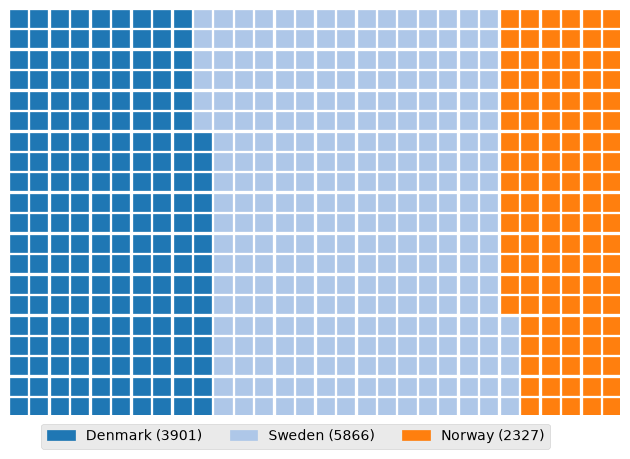

In [11]:
# Siapkan gambar grafik Waffle
fig = plt.figure(
    FigureClass=Waffle,
    rows=20,
    columns=30,  # masukkan jumlah baris dan kolom untuk waffle
    values=df_dsn["Total"],  # meneruskan data yang akan digunakan untuk ditampilkan
    cmap_name="tab20",  # skema warna
    legend={
        "labels": [f"{k} ({v})" for k, v in zip(df_dsn.index.values, df_dsn.Total)],
        "loc": "lower left",
        "bbox_to_anchor": (0.04, -0.1),
        "ncol": 3,
    },
    # perhatikan penggunaan list comprehension untuk membuat label
    # dari indeks dan total dataset
)

# Tampilkan grafik waffle
plt.savefig(
    "../outputs/waffle_proportions_immigrant_denmark_sweden_norway.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

**Pertanyaan:** Buatlah grafik Waffle untuk menampilkan proporsi kontribusi China dan India terhadap total imigrasi.

In [12]:
# buat dataframe baru untuk dua negara diatas
df_CI = df_canada.loc[["China", "India"], :]
df_CI.head()

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Country,,,,,,,,,,,,,,,,,,,,,
China,Asia,Eastern Asia,Developing regions,5123,6682,3308,1863,1527,1816,1960,...,42584,33518,27642,30037,29622,30391,28502,33024,34129,659962
India,Asia,Southern Asia,Developing regions,8880,8670,8147,7338,5704,4211,7150,...,36210,33848,28742,28261,29456,34235,27509,30933,33087,691904


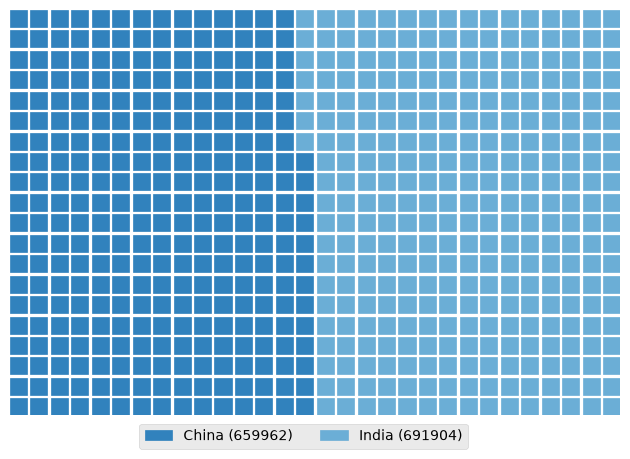

In [13]:
# buat grafik waffle dari dataframe tersebut
fig = plt.figure(
    FigureClass=Waffle,
    rows=20,
    columns=30,  # memasukkan jumlah baris dan kolom untuk waffle
    values=df_CI["Total"],  # meneruskan data yang digunakan untuk ditampilan
    cmap_name="tab20c",  # skema warna
    legend={
        "labels": [f"{k} ({v})" for k, v in zip(df_CI.index.values, df_CI.Total)],
        "loc": "lower left",
        "bbox_to_anchor": (0.2, -0.1),
        "ncol": 3,
    },
)

# tampilkan grafiknya
plt.savefig(
    "../outputs/waffle_proportions_immigrant_china_india.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

# Word Clouds <a id="3"></a>

`Word clouds` (juga dikenal sebagai awan teks atau awan tag) bekerja dengan cara sederhana: semakin sering sebuah kata tertentu muncul dalam sumber data tekstual (seperti pidato, postingan blog, atau basis data), semakin besar dan tebal kata tersebut muncul dalam awan kata.


Untungnya, sudah ada paket Python untuk menghasilkan awan kata. Paket tersebut, yang disebut `word_cloud`, dikembangkan oleh **Andreas Mueller**. Anda dapat mempelajari lebih lanjut tentang paket ini dengan mengikuti tautan ini [link](https://github.com/amueller/word_cloud/).

Mari kita gunakan paket ini untuk mempelajari cara menghasilkan awan kata untuk dokumen teks tertentu.

Pertama, instal pustakanya

In [14]:
# impor paket dan kumpulan stopword-nya
from wordcloud import STOPWORDS, WordCloud

print("Wordcloud imported!")

Wordcloud imported!


Awan kata (word cloud) umumnya digunakan untuk melakukan analisis dan visualisasi data teks tingkat tinggi. Oleh karena itu, mari kita menyimpang dari dataset imigrasi dan bekerja dengan contoh yang melibatkan analisis data teks. Mari kita coba menganalisis sebuah novel pendek karya **Lewis Carroll** berjudul *Alice's Adventures in Wonderland*. Mari kita unduh file *.txt* dari novel tersebut.

In [15]:
import urllib

# Buka file dan baca isinya ke dalam variabel alice_novel
alice_novel = (
    urllib.request.urlopen(
        "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/alice_novel.txt"
    )
    .read()
    .decode("utf-8")
)

Selanjutnya, mari kita gunakan stopword yang telah kita impor dari `word_cloud`. Kita menggunakan fungsi *set* untuk menghapus stopword yang berlebihan.

In [16]:
stopwords = set(STOPWORDS)

Buat objek word cloud dan hasilkan word cloud. Untuk mempermudah, mari kita hasilkan word cloud hanya menggunakan 2000 kata pertama dalam novel.

In [17]:
# membuat objek word cloud
alice_wc = WordCloud()

# hasilkan word cloud
alice_wc.generate(alice_novel)

Hebat! Sekarang setelah awan kata (word cloud) dibuat, mari kita visualisasikan.

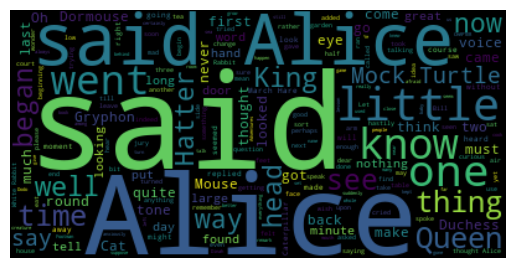

In [18]:
# menampilkan word cloud
plt.imshow(alice_wc, interpolation="bilinear")
plt.axis("off")
plt.show()

Menarik! Jadi, dalam 2000 kata pertama di novel tersebut, kata-kata yang paling sering muncul adalah **Alice**, **said**, **little**, **Queen**, dan seterusnya. Mari kita ubah ukuran awan kata agar kita dapat melihat kata-kata yang kurang sering muncul dengan lebih jelas.

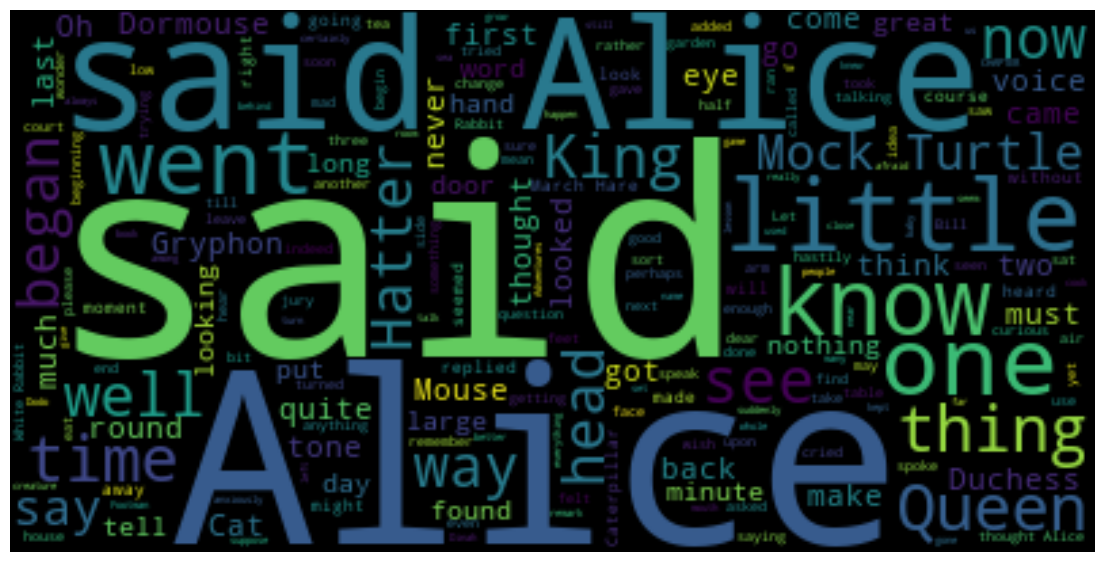

In [19]:
fig = plt.figure(figsize=(14, 18))

# tampilkan word cloud
plt.imshow(alice_wc, interpolation="bilinear")
plt.axis("off")
plt.savefig("../outputs/basic_word_clouds.png", dpi=200, bbox_inches="tight")
plt.show()

Jauh lebih baik! Namun, **said** sebenarnya bukan kata yang informatif. Jadi mari kita tambahkan ke daftar kata yang diabaikan (stopwords) dan buat ulang cloud-nya.

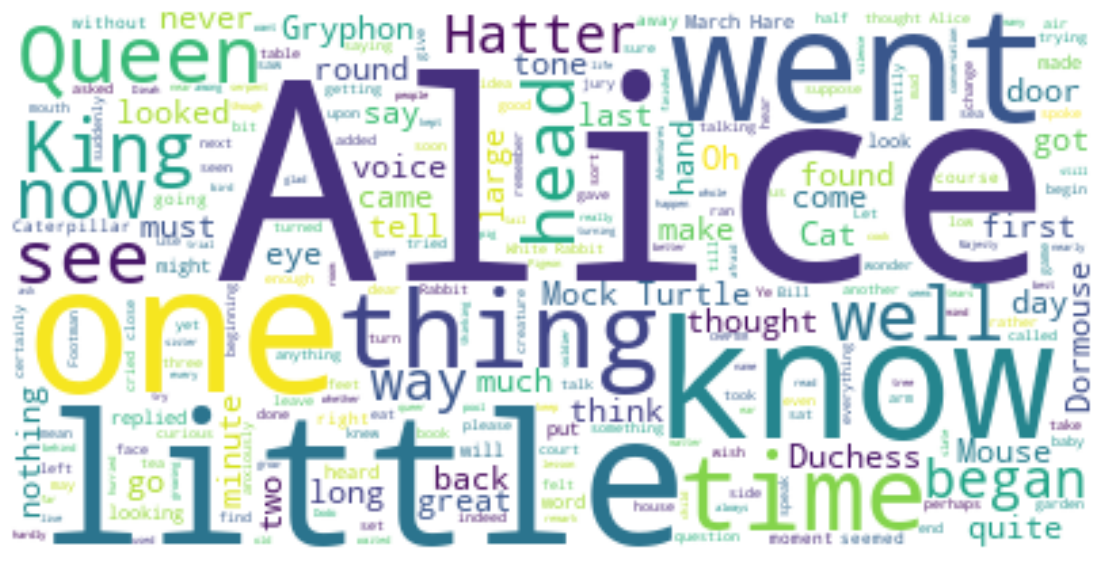

In [20]:
# tambahkan kata "said "ke stopwords
stopwords.add("said")

# buat ulang objek word cloud dengan stopwords yang sudah diperbarui
alice_wc = WordCloud(background_color="white", max_words=2000, stopwords=stopwords)

# hasilkan word cloud
alice_wc.generate(alice_novel)

# tampilkan word cloud
fig = plt.figure(figsize=(14, 18))
plt.imshow(alice_wc, interpolation="bilinear")
plt.axis("off")
plt.savefig("../outputs/stopwords_said_word_clouds.png", dpi=200, bbox_inches="tight")
plt.show()

Bagus sekali! Ini terlihat sangat menarik! Hal keren lain yang dapat Anda terapkan dengan paket `word_cloud` adalah menempatkan kata-kata di atas topeng dengan bentuk apa pun. Mari kita gunakan topeng Alice dan kelincinya. Kami sudah membuat topengnya untuk Anda, jadi mari kita unduh dan beri nama *alice_mask.png*.

In [21]:
# save mask to alice_mask
alice_mask = np.array(
    Image.open(
        urllib.request.urlopen(
            "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%204/images/alice_mask.png"
        )
    )
)

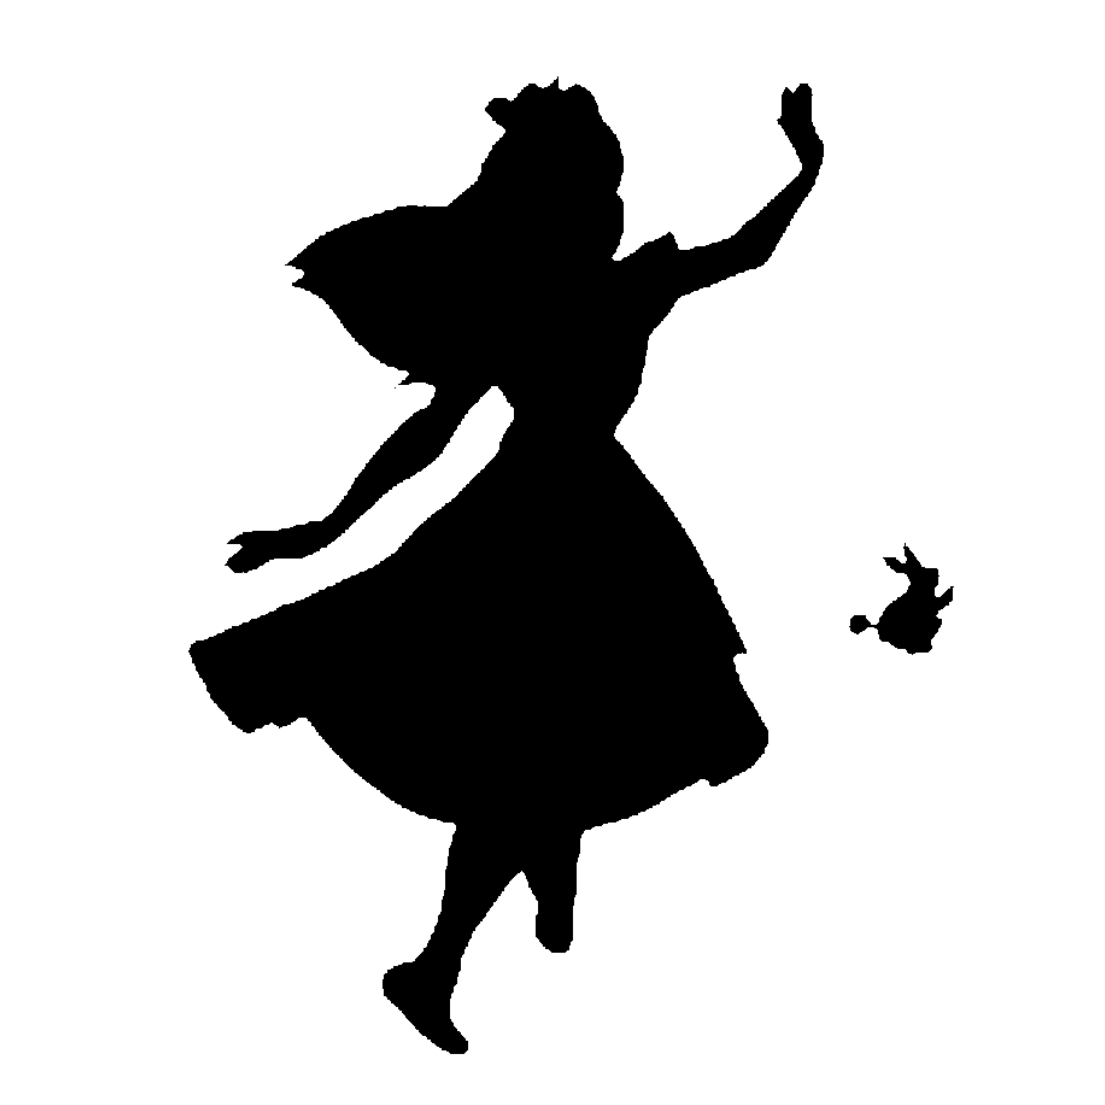

In [22]:
fig = plt.figure(figsize=(14, 18))

plt.imshow(alice_mask, cmap=plt.cm.gray, interpolation="bilinear")
plt.axis("off")
plt.show()

Membentuk awan kata sesuai dengan mask cukup mudah menggunakan paket `word_cloud`. Untuk mempermudah, kita akan terus menggunakan 2000 kata pertama dalam novel tersebut.

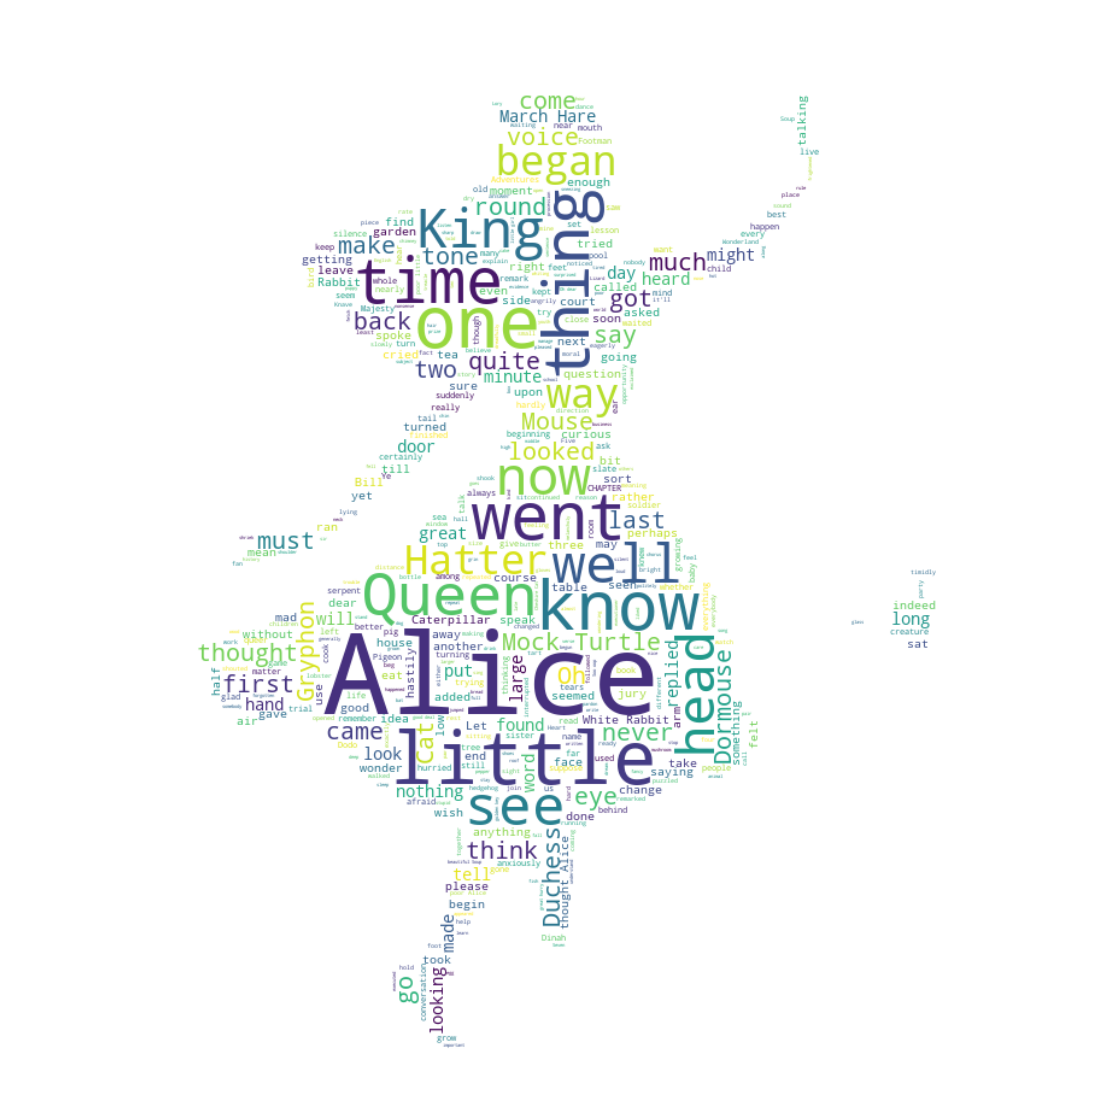

In [23]:
# buat ulang objek word cloud dengan tambahan masking (alice_mask)
alice_wc = WordCloud(
    background_color="white",
    max_words=2000,
    mask=alice_mask,
    stopwords=stopwords,
)

# hasilkan word cloud
alice_wc.generate(alice_novel)

# tampilkan word cloud
fig = plt.figure(figsize=(14, 18))
plt.imshow(alice_wc, interpolation="bilinear")
plt.axis("off")

plt.savefig("../outputs/masking_word_clouds.png", dpi=200, bbox_inches="tight")
plt.show()

Sayangnya, data imigrasi kita tidak memiliki data teks, tetapi di mana ada kemauan, di situ ada jalan. Mari kita hasilkan contoh data teks dari dataset imigrasi kita, misalnya data teks sebanyak 90 kata.

Mari kita ingat kembali bagaimana tampilan data kita.

In [24]:
df_canada.head()

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Country,,,,,,,,,,,,,,,,,,,,,
Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,496,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,1,...,1223,856,702,560,716,561,539,620,603,15699
Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,69,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,2,...,0,1,1,0,0,0,0,1,1,15


Lalu berapa total imigrasi dari tahun 1980 hingga 2013?

In [25]:
total_immigrants = df_canada["Total"].sum()
total_immigrants

np.int64(6409153)

Dengan menggunakan negara-negara yang namanya terdiri dari satu kata, mari kita gandakan nama setiap negara berdasarkan seberapa besar kontribusi mereka terhadap total imigrasi.

In [26]:
max_words = 90
word_string = ""

for country in df_canada.index.values:
    # periksa apakah nama negara merupakan nama satu kata
    if country.count(" ") == 0:
        repeat_num_times = int(
            df_canada.loc[country, "Total"] / total_immigrants * max_words
        )
        word_string = word_string + ((country + " ") * repeat_num_times)

# menampilkan teks yang dihasilkan
word_string

'China China China China China China China China China Colombia Egypt France Guyana Haiti India India India India India India India India India Jamaica Lebanon Morocco Pakistan Pakistan Pakistan Philippines Philippines Philippines Philippines Philippines Philippines Philippines Poland Portugal Romania '

Kita tidak berurusan dengan kata-kata penghenti (stopwords) di sini, jadi tidak perlu melewatinya saat membuat word cloud.

In [27]:
# buat word cloud
wordcloud = WordCloud(background_color="white").generate(word_string)
print("Word Cloud created!")

Word Cloud created!


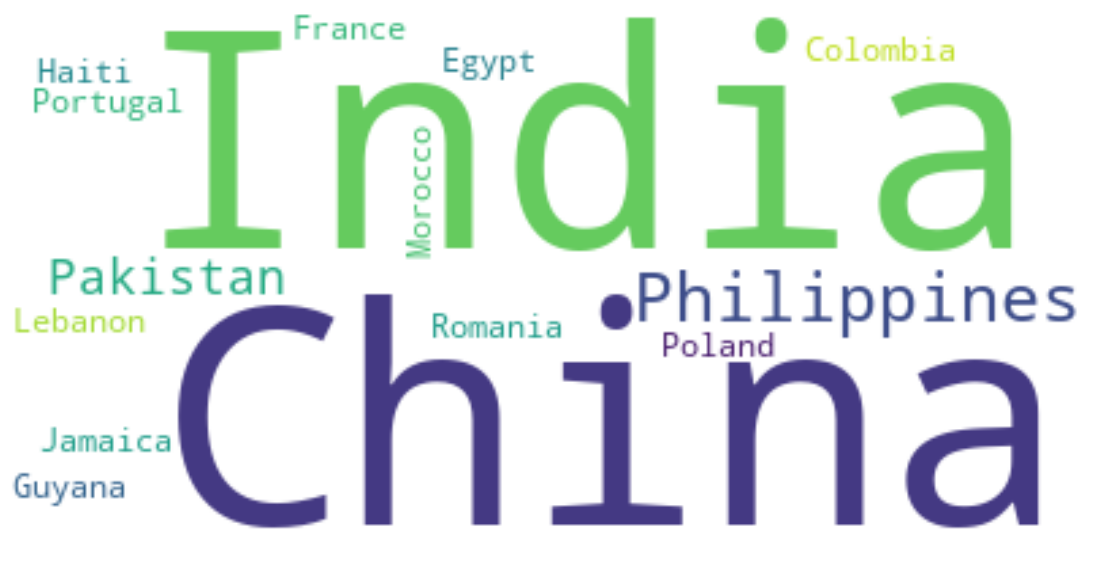

In [28]:
# tampilkan word cloud
plt.figure(figsize=(14, 18))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")

plt.savefig(
    "../outputs/total_immigrations_word_clouds.png", dpi=200, bbox_inches="tight"
)
plt.show()

Berdasarkan word cloud di atas, tampaknya mayoritas imigran berasal dari salah satu dari 15 negara yang ditampilkan oleh word cloud tersebut. Salah satu visual menarik yang bisa Anda buat adalah dengan menggunakan peta Kanada dan masker, lalu menempatkan word cloud di atas peta Kanada. Itu akan menjadi visual yang menarik untuk dibuat!

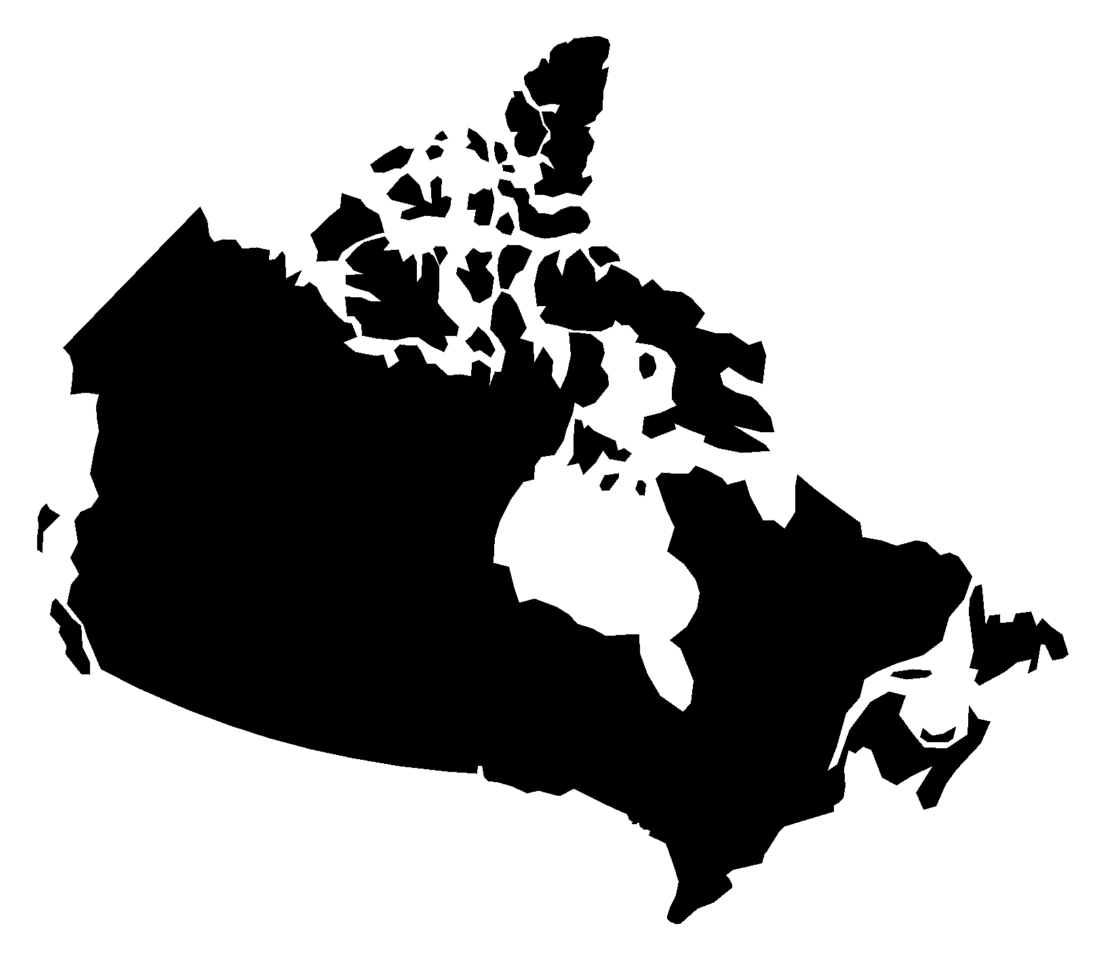

In [29]:
# buat masking dari map canada
canada_mask = np.array(Image.open("../outputs/canada.png"))

# tampilkan masking
plt.figure(figsize=(14, 18))
plt.imshow(canada_mask, interpolation="bilinear")
plt.axis("off")

plt.show()

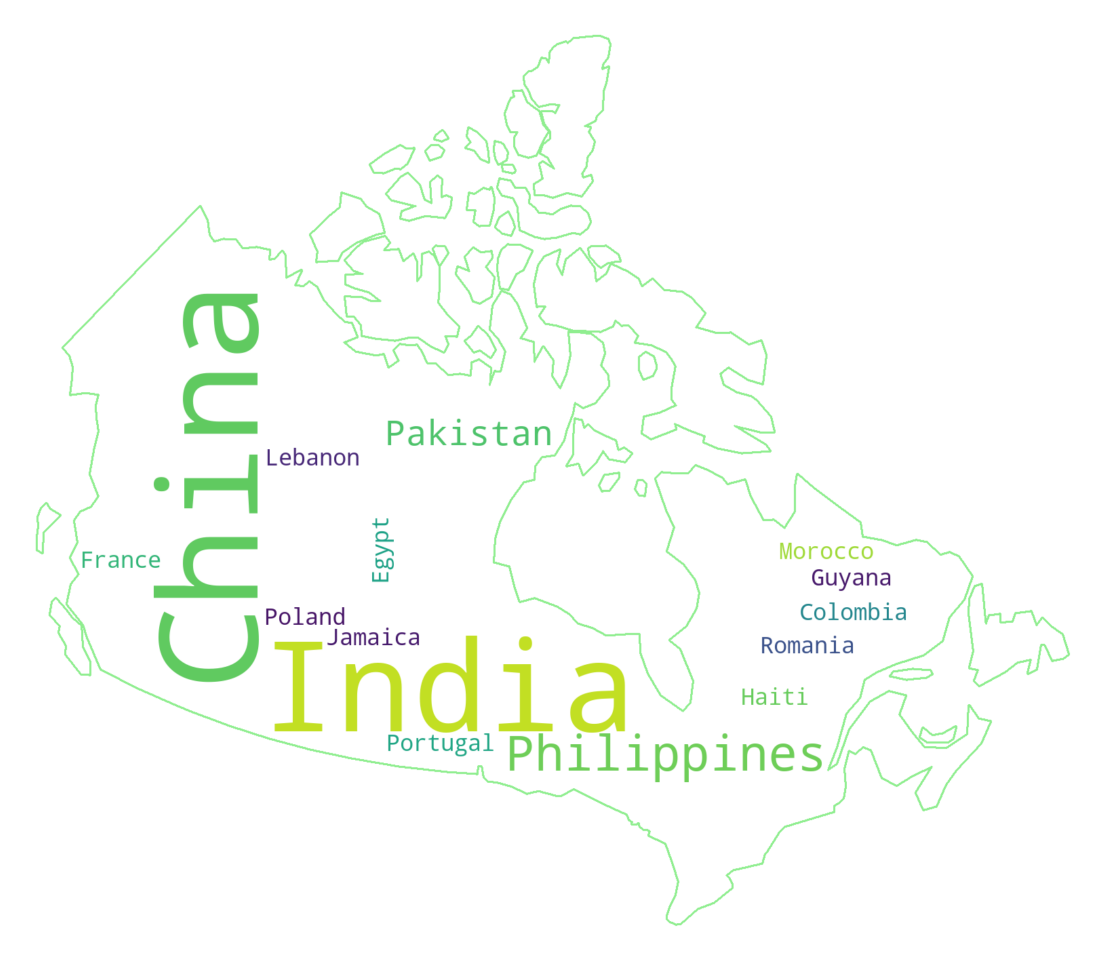

In [30]:
# buat object word cloud baru dengan tambahan masking
immigrant_wordcloud = WordCloud(
    background_color="white",
    mask=canada_mask,
    contour_width=2,
    contour_color="lightgreen",
).generate(word_string)

# tampilkan word cloud
plt.figure(figsize=(14, 18))
plt.imshow(immigrant_wordcloud, interpolation="bilinear")
plt.axis("off")

plt.savefig(
    "../outputs/masking_total_immigrations_word_clouds.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

# Plotting with Seaborn <a id="4"></a>

> Seaborn adalah pustaka visualisasi Python yang berbasis pada matplotlib. Pustaka ini menyediakan antarmuka tingkat tinggi untuk menggambar grafik statistik yang menarik. Anda dapat mempelajari lebih lanjut tentang *seaborn* dengan mengikuti tautan ini [link](https://seaborn.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01) dan informasi lebih lanjut tentang plot regresi *seaborn* dapat ditemukan dengan mengikuti tautan ini [link](http://seaborn.pydata.org/generated/seaborn.regplot.html?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01).

Dalam praktikum *Pie Charts, Box Plots, Scatter Plots, and Bubble Plots*, kita mempelajari cara membuat scatter plot dan kemudian menyesuaikan regresion line. Hanya dibutuhkan sekitar 20 baris kode untuk membuat diagram sebar beserta penyesuaian regresinya. Di bagian terakhir ini, kita akan menjelajahi *seaborn* dan melihat seberapa efisiennya dalam membuat garis regresi dan penyesuaian menggunakan pustaka ini!

### Categorical Plots
Dalam data 'df_canada' kita, mari kita cari tahu berapa banyak benua yang disebutkan.


In [31]:
df_canada["Continent"].unique()

<StringArray>
[                           'Asia',                          'Europe',
                          'Africa',                         'Oceania',
 'Latin America and the Caribbean',                'Northern America']
Length: 6, dtype: str

### countplot
**Plot hitungan (count plot) dapat dianggap sebagai histogram yang melintasi variabel kategorikal, bukan kuantitatif.**

Mari kita cari jumlah Continent dalam data 'df_canada' menggunakan countplot pada 'Continent'.


<Axes: xlabel='Continent', ylabel='count'>

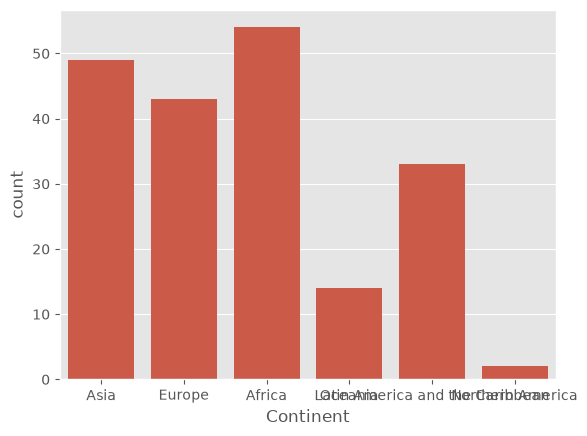

In [32]:
sns.countplot(data=df_canada, x="Continent")

Label pada sumbu x tidak terlihat seperti yang diharapkan.<br>Mari kita coba mengganti 'Latin America and the Caribbean' dengan "L-America", 'Northern America' dengan "N-America",<br>dan mengubah ukuran gambar lalu menampilkan plot lagi.

In [33]:
df_canada1 = df_canada.replace("Latin America and the Caribbean", "L-America")
df_canada1 = df_canada1.replace("Northern America", "N-America")

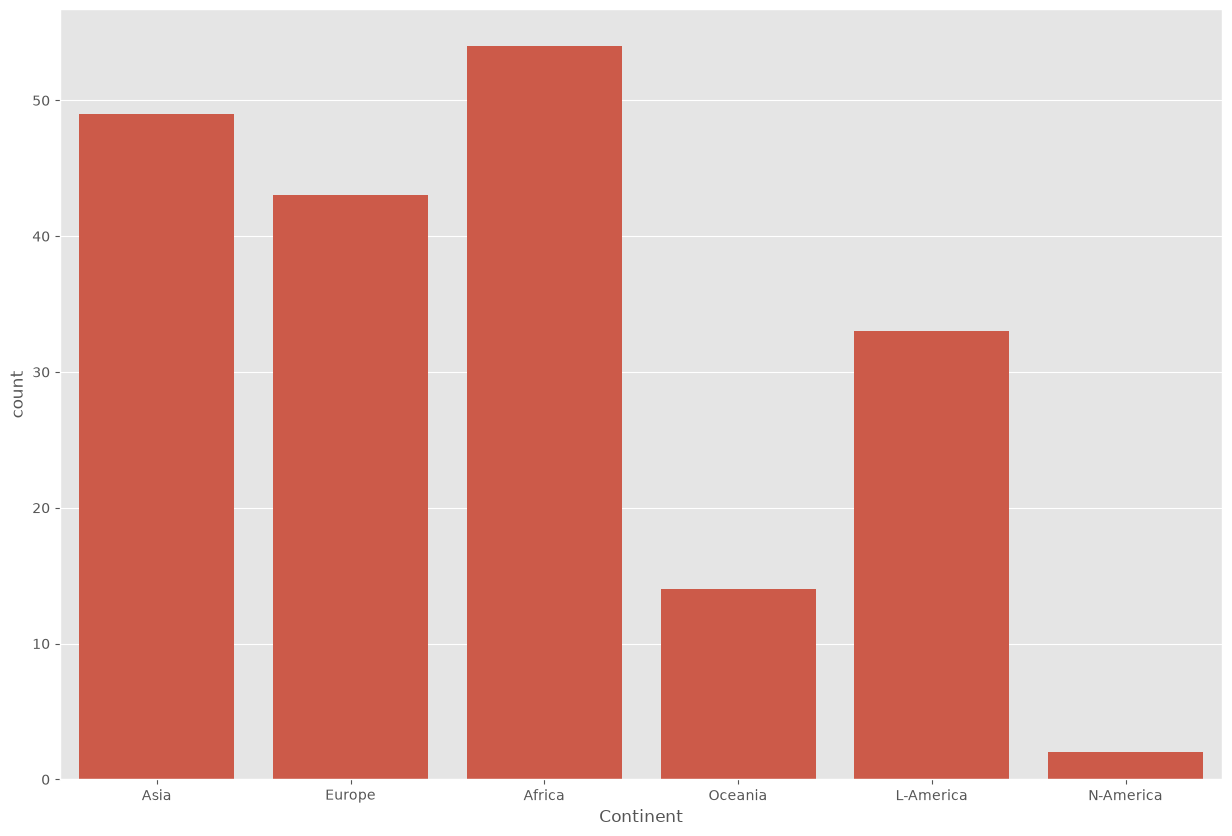

In [34]:
# Tampilkan plot
plt.figure(figsize=(15, 10))
sns.countplot(data=df_canada1, x="Continent")

plt.savefig("../outputs/seaborn_count_plot_continent.png", dpi=200, bbox_inches="tight")
plt.show()

### Barplot
**Plot ini akan melakukan Groupby pada variabel kategorikal dan memplot nilai agregat, dengan confidence intervals**.<br> Mari kita plot total imigran berdasarkan Benua (Continent).


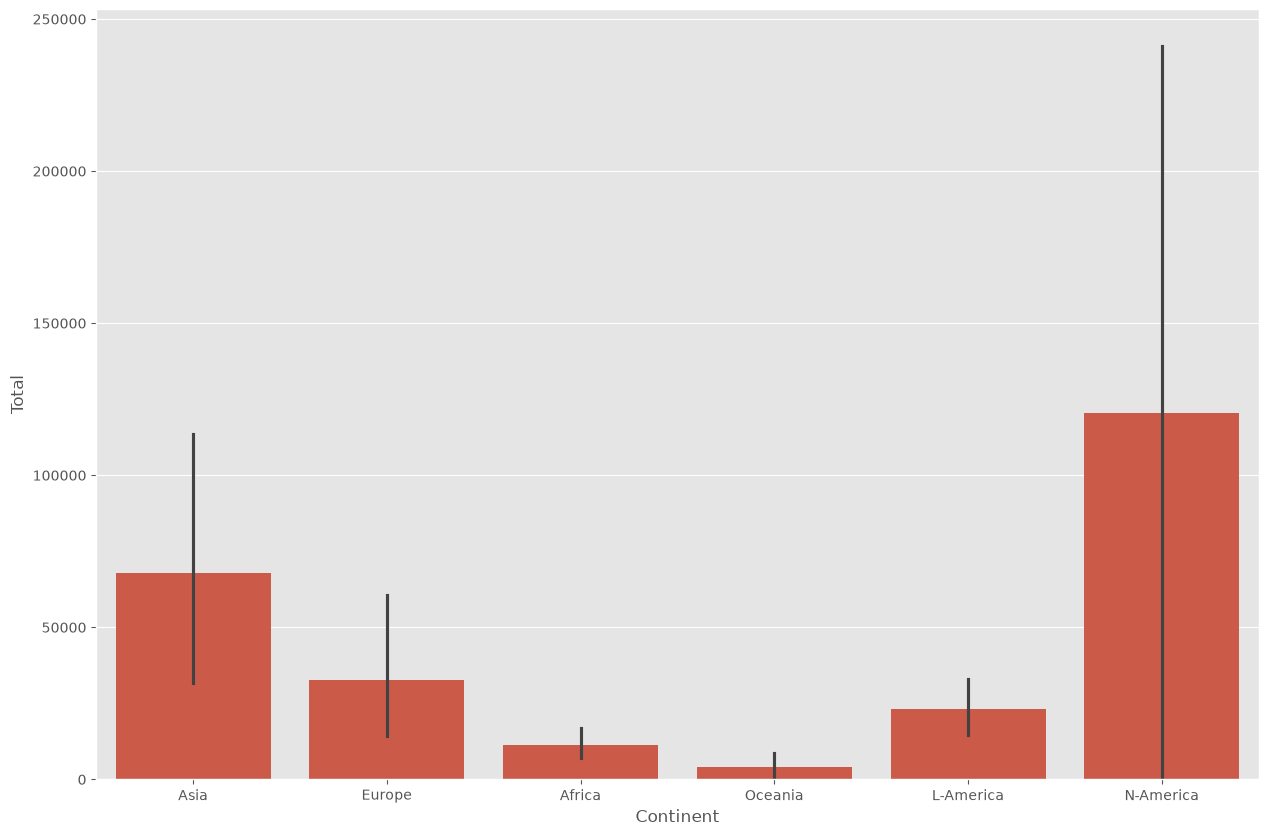

In [35]:
plt.figure(figsize=(15, 10))
sns.barplot(data=df_canada1, x="Continent", y="Total")

plt.savefig(
    "../outputs/seaborn_bar_plot_total_continent.png", dpi=200, bbox_inches="tight"
)
plt.show()

Anda dapat memverifikasi nilainya dengan melakukan pengelompokan (groupby) pada Total dan Benua (Continent) untuk mean().

In [36]:
df_canada2 = df_canada1.groupby("Continent")["Total"].mean()
df_canada2

Continent
Africa        11462.000000
Asia          67710.081633
Europe        32812.720930
L-America     23186.303030
N-America    120571.000000
Oceania        3941.000000
Name: Total, dtype: float64

Buatlah dataframe baru yang menyimpan jumlah total imigran yang mendarat di Kanada per tahun dari tahun 1980 hingga 2013.

# Regression Plot <a id="5"></a>
Dengan *seaborn*, menghasilkan plot regresi semudah memanggil fungsi **regplot**.


In [37]:
years = list(map(str, range(1980, 2014)))

# kita dapat menggunakan metode sum() untuk mendapatkan total populasi per tahun
df_total = pd.DataFrame(df_canada[years].sum(axis=0))
df_total.head()

,0
1980,99137
1981,110563
1982,104271
1983,75550
1984,73417


In [38]:
# ubah tahun menjadi tipe float (berguna untuk regresi di kemudian hari)
df_total.index = map(float, df_total.index)

# mengatur ulang indeks untuk memasukkannya kembali sebagai kolom dalam dataframe df_total
df_total.reset_index(inplace=True)
df_total.head()

,index,0
0,1980.0,99137
1,1981.0,110563
2,1982.0,104271
3,1983.0,75550
4,1984.0,73417


In [39]:
# ganti nama kolom
df_total.columns = ["years", "total"]

# lihat dataframe akhir
df_total.head()

,years,total
0,1980.0,99137
1,1981.0,110563
2,1982.0,104271
3,1983.0,75550
4,1984.0,73417


<Axes: xlabel='years', ylabel='total'>

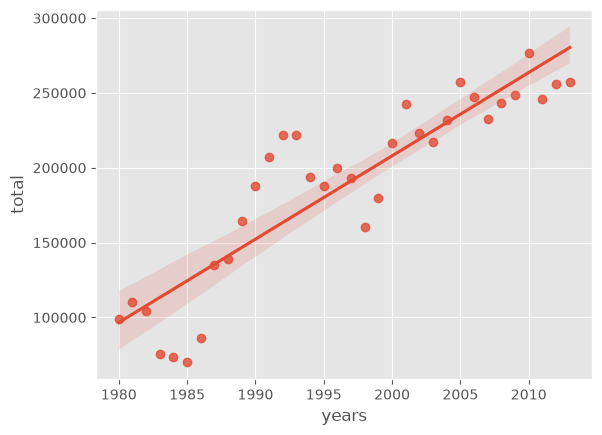

In [40]:
# seaborn sudah diimpor sejak awal lab ini.
sns.regplot(data=df_total, x="years", y="total")

Ini bukan sihir; ini *seaborn*! Anda juga dapat menyesuaikan warna plot sebaran dan garis regresi. Mari kita ubah warnanya menjadi hijau.

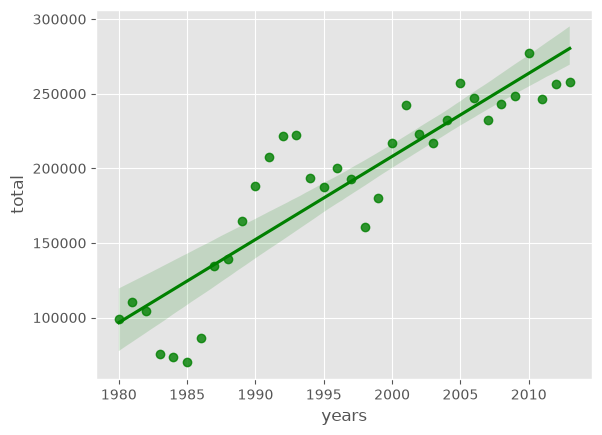

In [41]:
sns.regplot(data=df_total, x="years", y="total", color="green")
plt.show()

Anda selalu dapat menyesuaikan bentuk penanda, jadi alih-alih penanda lingkaran, mari kita gunakan `+`.

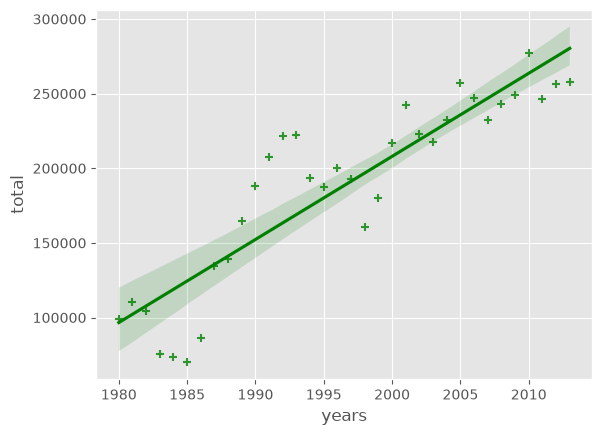

In [42]:
sns.regplot(data=df_total, x="years", y="total", color="green", marker="+")
plt.show()

Mari kita kembangkan sedikit alur ceritanya agar lebih menarik secara visual.

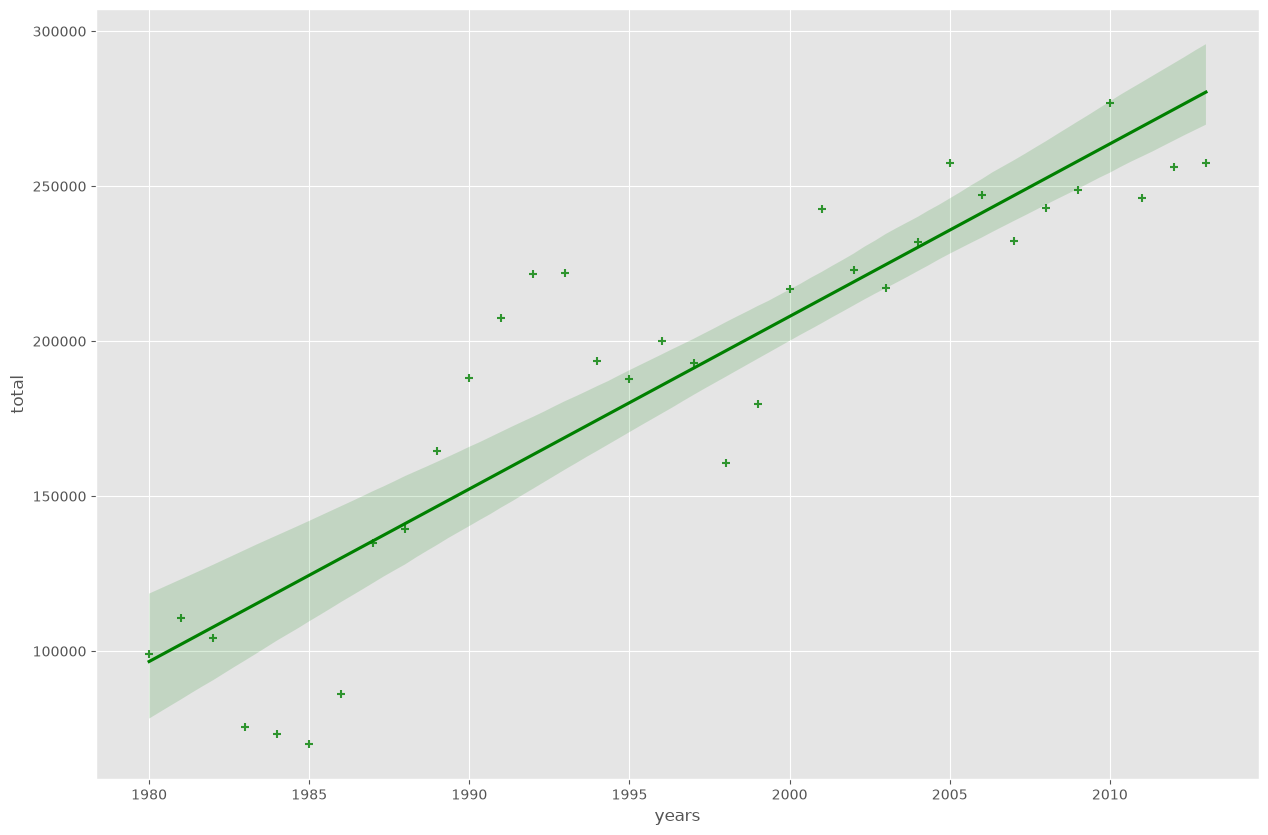

In [43]:
plt.figure(figsize=(15, 10))
sns.regplot(data=df_total, x="years", y="total", color="green", marker="+")
plt.show()

Dan mari kita perbesar ukuran penanda agar sesuai dengan ukuran gambar yang baru, dan tambahkan judul serta label x dan y.

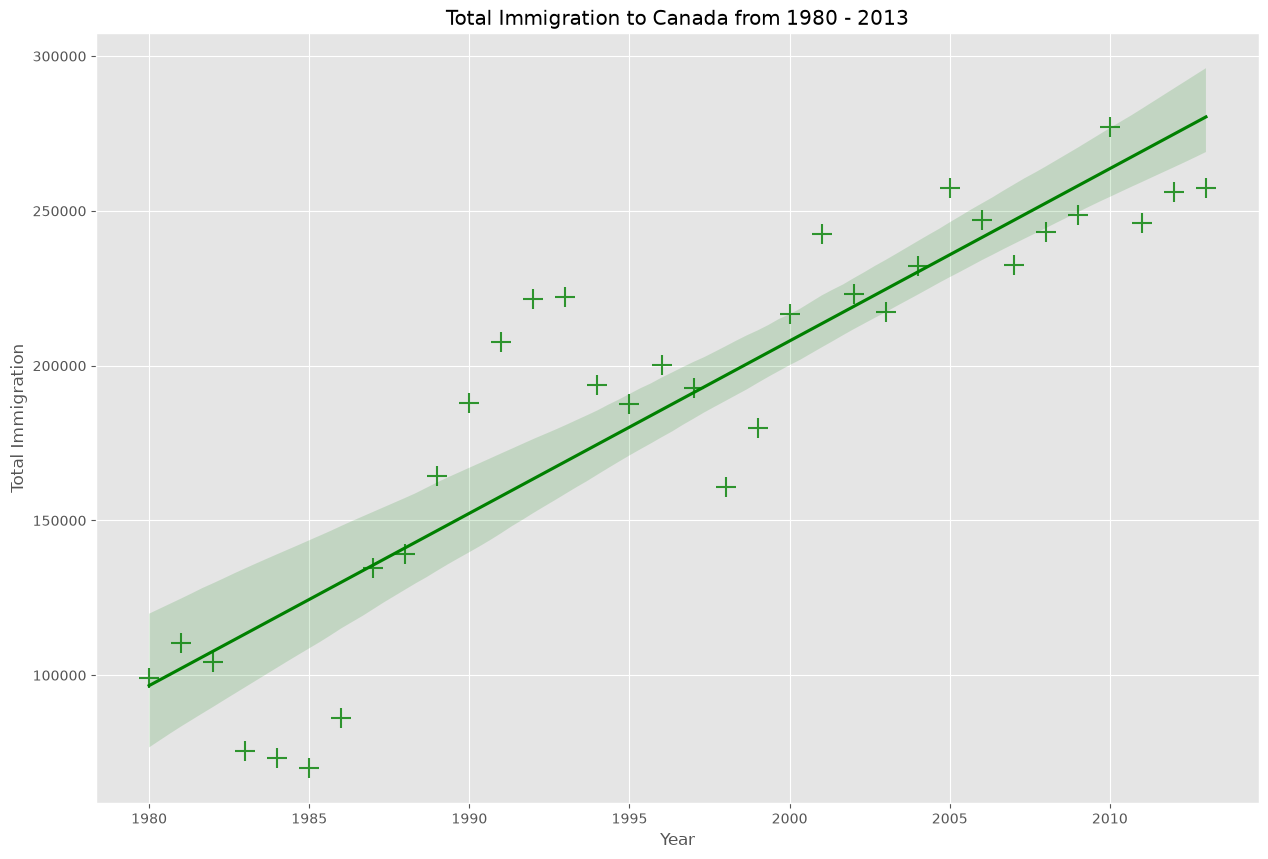

In [44]:
plt.figure(figsize=(15, 10))

ax = sns.regplot(
    data=df_total,
    x="years",
    y="total",
    color="green",
    marker="+",
    scatter_kws={"s": 200},
)
ax.set(xlabel="Year", ylabel="Total Immigration")
ax.set_title("Total Immigration to Canada from 1980 - 2013")

plt.show()

Dan terakhir, perbesar ukuran font label tanda centang, judul, dan label x dan y agar tidak terlihat terabaikan!

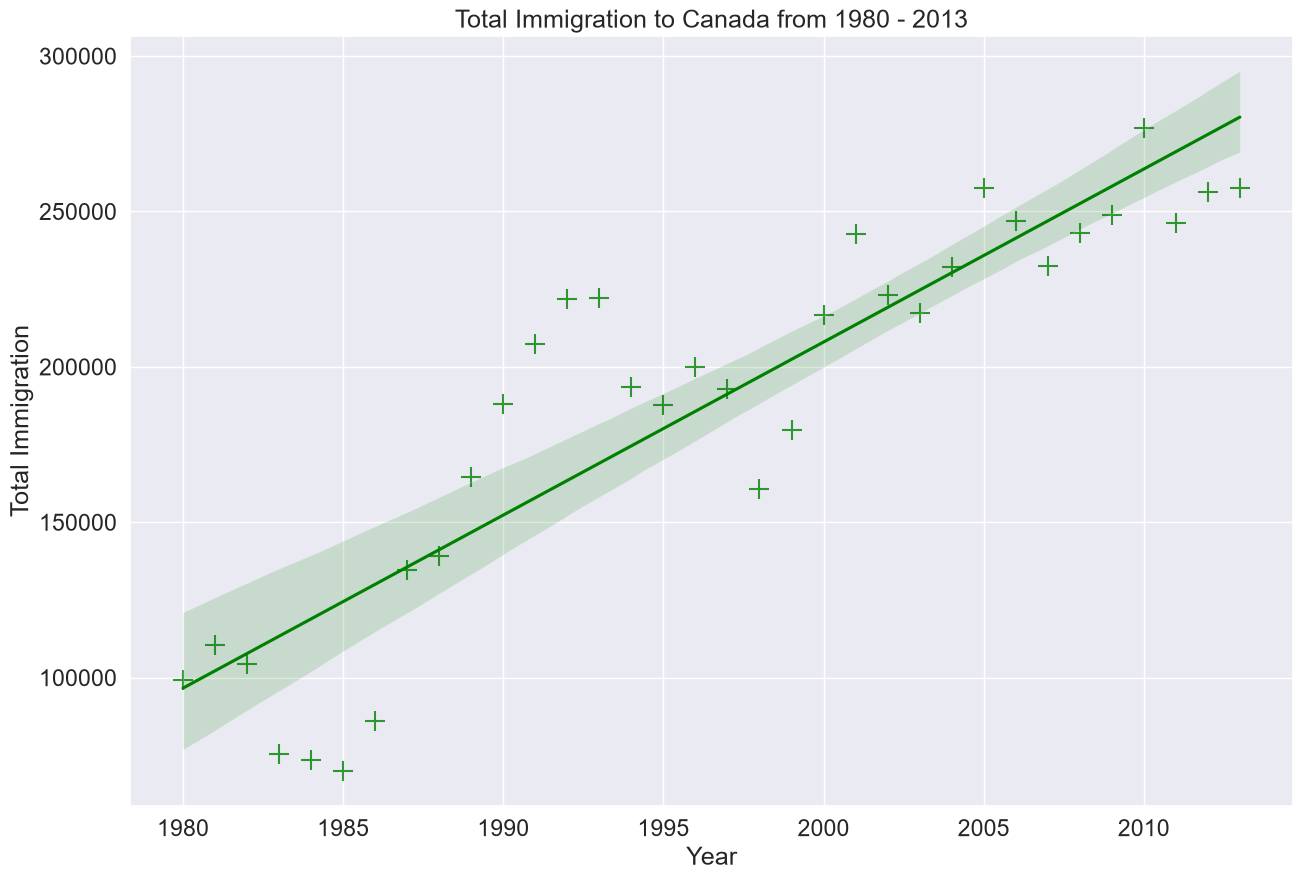

In [45]:
plt.figure(figsize=(15, 10))

sns.set(font_scale=1.5)

ax = sns.regplot(
    data=df_total,
    x="years",
    y="total",
    color="green",
    marker="+",
    scatter_kws={"s": 200},
)
ax.set(xlabel="Year", ylabel="Total Immigration")
ax.set_title("Total Immigration to Canada from 1980 - 2013")

plt.savefig(
    "../outputs/seaborn_regression_plot_total_immigrants.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

Luar biasa! Sebuah scatter plot lengkap dengan regresi yang sesuai hanya dengan 5 baris kode. Bukankah ini sangat menakjubkan?

Jika Anda kurang menyukai latar belakang ungu, Anda dapat dengan mudah mengubah gayanya menjadi latar belakang putih polos.

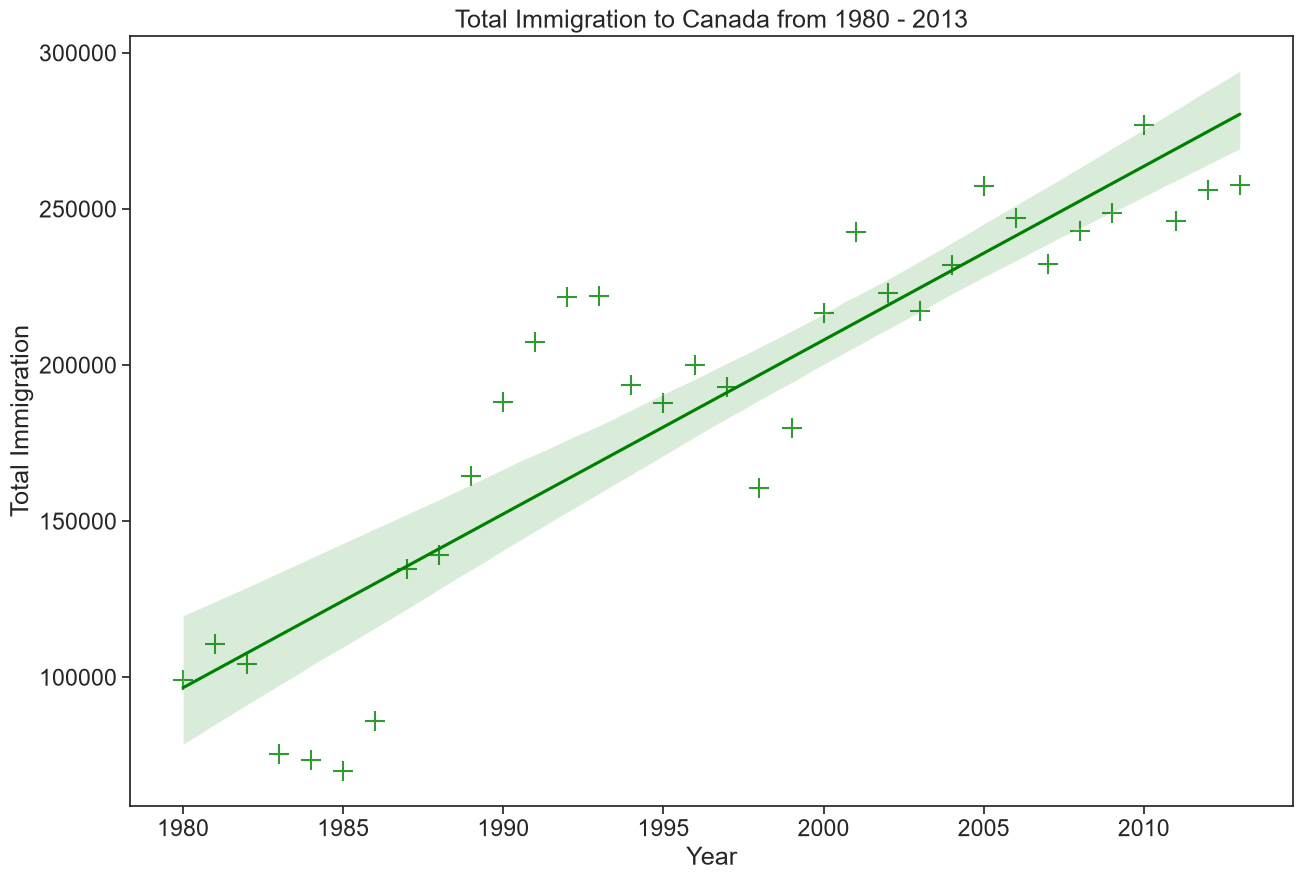

In [46]:
plt.figure(figsize=(15, 10))

sns.set(font_scale=1.5)
sns.set_style("ticks")  # background putih polos

ax = sns.regplot(
    data=df_total,
    x="years",
    y="total",
    color="green",
    marker="+",
    scatter_kws={"s": 200},
)
ax.set(xlabel="Year", ylabel="Total Immigration")
ax.set_title("Total Immigration to Canada from 1980 - 2013")

plt.savefig(
    "../outputs/seaborn_regression_plot_total_immigrants_ticks_bg.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

Atau dengan latar belakang putih bergaris-garis.

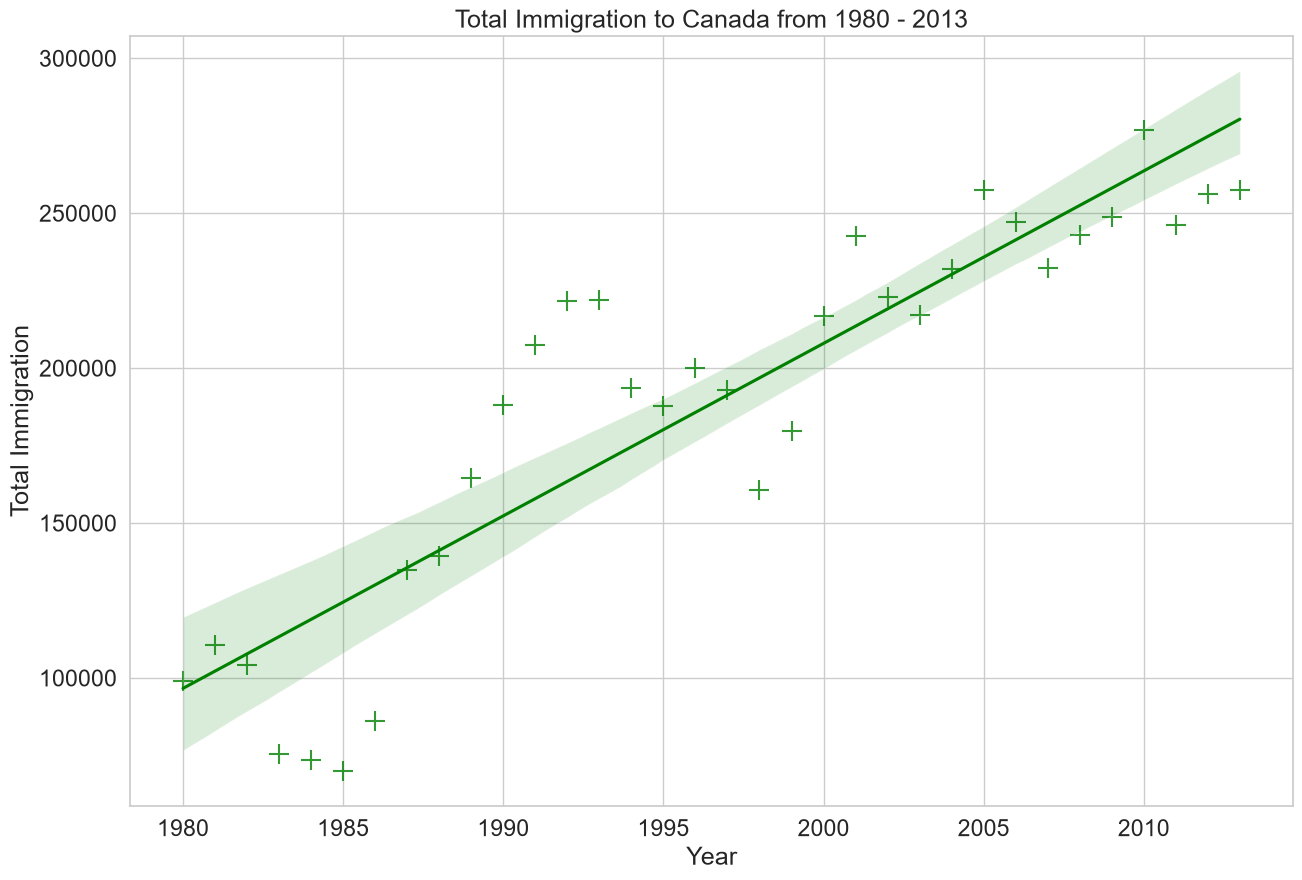

In [47]:
plt.figure(figsize=(15, 10))

sns.set(font_scale=1.5)
sns.set_style("whitegrid")  # background putih dengan grid

ax = sns.regplot(
    data=df_total,
    x="years",
    y="total",
    color="green",
    marker="+",
    scatter_kws={"s": 200},
)
ax.set(xlabel="Year", ylabel="Total Immigration")
ax.set_title("Total Immigration to Canada from 1980 - 2013")

plt.savefig(
    "../outputs/seaborn_regression_plot_total_immigrants_whitegrid_bg.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

**Pertanyaan**: Gunakan seaborn untuk membuat scatter plot dengan regression line untuk memvisualisasikan total imigrasi dari Denmark, Sweden, dan Norway ke Canada dari tahun 1980 hingga 2013.

In [48]:
# buat dataframe baru untuk ketiga negara diatas
nyears = list(map(str, range(1980, 2014)))

df_dsn = df_canada.loc[["Denmark", "Sweden", "Norway"], nyears].T
df_dsn.head()

Country,Denmark,Sweden,Norway
1980,272,281,116
1981,293,308,77
1982,299,222,106
1983,106,176,51
1984,93,128,31


In [49]:
# gunakan metode sum() untuk mendapatkan total populasi dari ketiga negara per tahun
df_dsn = pd.DataFrame(df_dsn.sum(axis=1))
df_dsn.head()

,0
1980,669
1981,678
1982,627
1983,333
1984,252


In [50]:
# ubah tahun menjadi tipe float (berguna untuk regresi di kemudian hari)
df_dsn.index = map(int, df_dsn.index)

# mengatur ulang indeks untuk memasukkannya kembali sebagai kolom dalam dataframe baru
df_dsn.reset_index(inplace=True)
df_dsn.head()

,index,0
0,1980,669
1,1981,678
2,1982,627
3,1983,333
4,1984,252


In [51]:
# hapus nama kolom index
df_dsn.index.name = None

# ubah nama kolom
df_dsn.columns = ["years", "total"]
df_dsn.head()

,years,total
0,1980,669
1,1981,678
2,1982,627
3,1983,333
4,1984,252


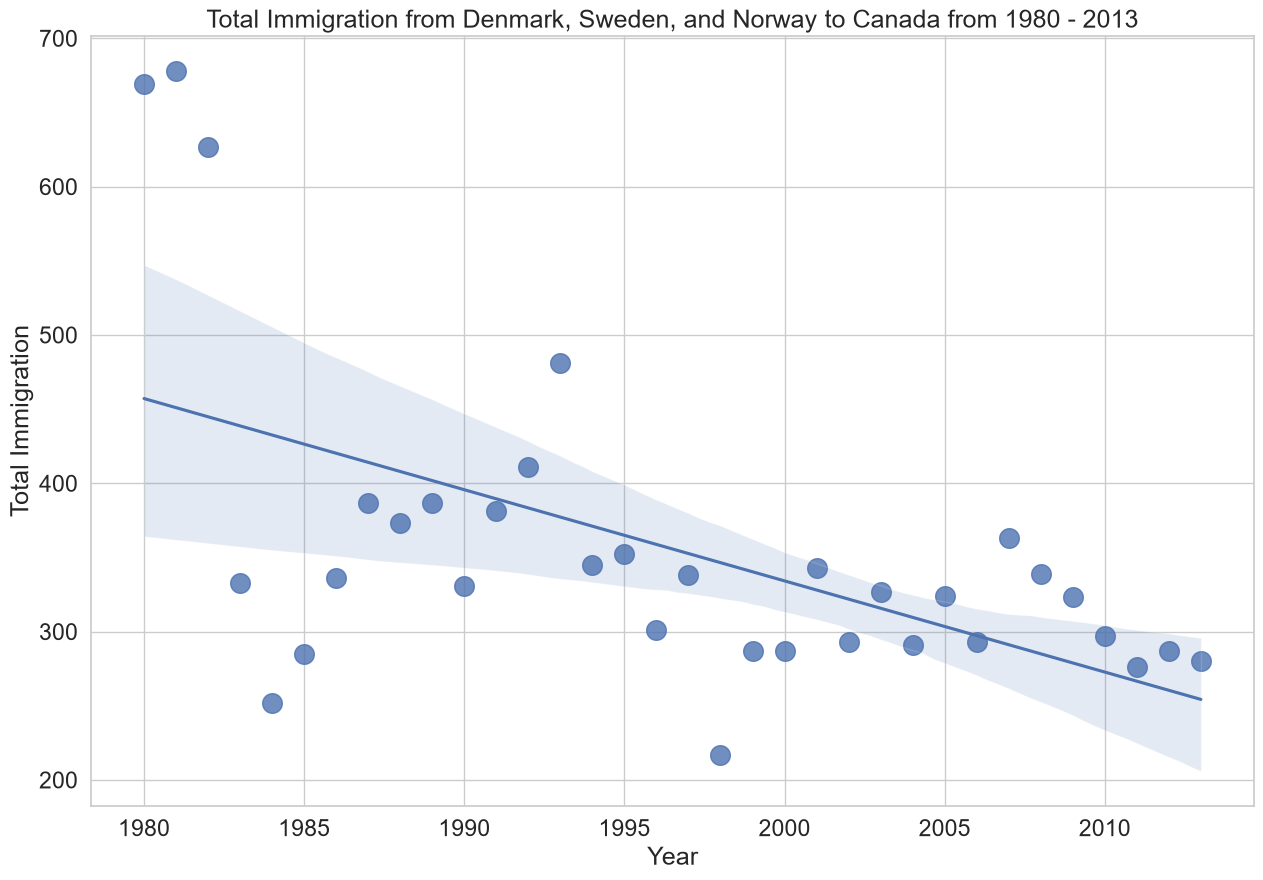

In [53]:
# buat regression plot
plt.figure(figsize=(15, 10))

sns.set(font_scale=1.5)
sns.set_style("whitegrid")

ax = sns.regplot(data=df_dsn, x="years", y="total", scatter_kws={"s": 200})
ax.set(xlabel="Year", ylabel="Total Immigration")
ax.set_title("Total Immigration from Denmark, Sweden, and Norway to Canada from 1980 - 2013")

plt.savefig("../outputs/seaborn_regression_plot_total_immigrants_three_countries.png", dpi=200, bbox_inches="tight")
plt.show()